In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import autocorrelation_plot
import os
from pathlib import Path
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose

# Настройка стиля графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


In [47]:
FILE_PATH = "Steel_industry_data.csv"

def load_and_audit_data(path: str) -> pd.DataFrame:
    """Загружает данные с обработкой различных кодировок и разделителей."""
    
    # Проверка существования файла
    if not Path(path).exists():
        print(f"ОШИБКА: Файл '{path}' не найден!")
        print(f"Текущая директория: {os.getcwd()}")
        print(f"Файлы CSV в директории: {[f for f in os.listdir('.') if f.endswith('.csv')]}")
        return None
    
    print(f"Загрузка файла: {path}")
    print(f"Размер файла: {Path(path).stat().st_size / 1024:.2f} KB")
    
    # Попытки загрузки с разными кодировками и разделителями
    encodings = ['utf-8', 'latin1', 'cp1251', 'iso-8859-1']
    separators = [',', ';', '\t']
    
    for encoding in encodings:
        for sep in separators:
            try:
                print(f"  → Пробуем: encoding='{encoding}', sep='{sep}'")
                df = pd.read_csv(path, encoding=encoding, sep=sep)
                
                # Проверка, что загрузилось корректно (должно быть несколько столбцов)
                if df.shape[1] > 1:
                    print(f" Успешно загружено!")
                    break
                else:
                    print(f" Только 1 столбец, пробуем другой разделитель...")
            except Exception as e:
                continue
        else:
            continue
        break
    else:
        print("Не удалось загрузить файл ни с одной из комбинаций кодировки/разделителя")
        return None
    
    print(f"\nРазмер датасета: {df.shape[0]:,} строк, {df.shape[1]} столбцов")
    
    print("\n--- Первые 5 строк ---")
    display(df.head())
    
    print("\n--- Информация о типах данных ---")
    df.info()
    
    print("\n--- Проверка на пропущенные значения ---")
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print(missing[missing > 0])
    else:
        print("Пропуски отсутствуют")
    
    print("\n--- Проверка на дубликаты ---")
    duplicates_count = df.duplicated().sum()
    print(f"Найдено дубликатов: {duplicates_count:,}")
    
    return df

# Запуск
df = load_and_audit_data(FILE_PATH)

if df is not None:
    print("\nДанные успешно загружены и готовы к анализу!")
else:
    print("\nНе удалось загрузить данные. Проверьте файл и повторите попытку.")

Загрузка файла: Steel_industry_data.csv
Размер файла: 2667.37 KB
  → Пробуем: encoding='utf-8', sep=','
 Успешно загружено!

Размер датасета: 35,040 строк, 11 столбцов

--- Первые 5 строк ---


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load



--- Информация о типах данных ---
<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  str    
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  str    
 9   Day_of_week                           35040 non-null  str    
 10  Load_Type                             35040 non-null  str 

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.00,35040.00,35040.00,35040.00,35040.00,35040.00,35040.00
mean,27.39,13.04,3.87,0.01,80.58,84.37,42750.00
std,33.44,16.31,7.42,0.02,18.92,30.46,24940.53
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,3.20,2.30,0.00,0.00,63.32,99.70,21375.00
50%,4.57,5.00,0.00,0.00,87.96,100.00,42750.00
75%,51.24,22.64,2.09,0.02,99.02,100.00,64125.00
max,157.18,96.91,27.76,0.07,100.00,100.00,85500.00


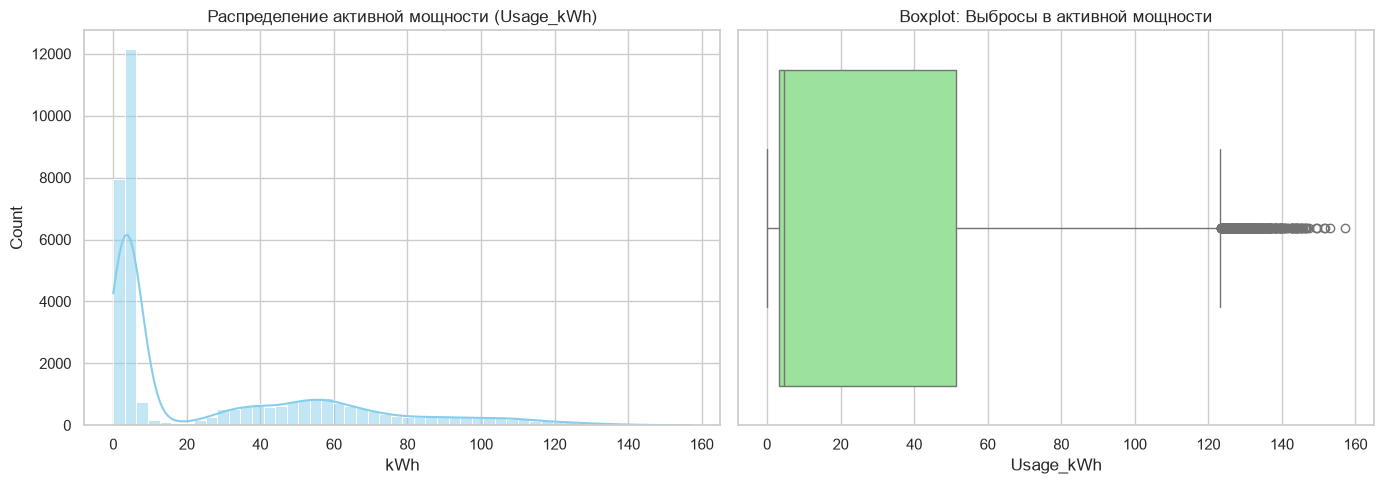

In [48]:
# Преобразуем дату в формат datetime и делаем её индексом
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M', dayfirst=True)
df = df.set_index('date').sort_index()

# Базовая статистика по числовым признакам
display(df.describe().round(2))

# Визуализация распределения Usage_kWh
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Usage_kWh'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение активной мощности (Usage_kWh)')
axes[0].set_xlabel('kWh')

# Boxplot для выявления выбросов
sns.boxplot(x=df['Usage_kWh'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot: Выбросы в активной мощности')

plt.tight_layout()
plt.show()

In [49]:
# Проверка целостности временного ряда

# Ожидаемые временные метки при 15-минутной дискретности
expected_freq = pd.DateOffset(minutes=15)
date_range_expected = pd.date_range(start=df.index.min(), end=df.index.max(), freq=expected_freq)
missing_timestamps = date_range_expected.difference(df.index)

print(f"Период данных: {df.index.min()} → {df.index.max()}")
print(f"Ожидаемое количество записей (96 в день): {len(date_range_expected):,}")
print(f"Фактическое количество записей: {len(df):,}")
print(f"Пропущенные временные метки: {len(missing_timestamps)}")

if len(missing_timestamps) > 0:
    print("\nПример пропущенных интервалов:")
    display(missing_timestamps[:10])
    
    plt.figure(figsize=(14, 4))
    plt.plot(df.index, (~df.index.isin(missing_timestamps)).astype(int), linewidth=0.5)
    plt.title('Целостность временного ряда (1 = данные есть, 0 = пропуск)')
    plt.xlabel('Дата')
    plt.ylabel('Наличие данных')
    plt.yticks([0, 1], ['Пропуск', 'Есть данные'])
    plt.tight_layout()
    plt.show()
else:
    print("Временной ряд целостный — пропущенных 15-минутных интервалов нет.")

Период данных: 2018-01-01 00:00:00 → 2018-12-31 23:45:00
Ожидаемое количество записей (96 в день): 35,040
Фактическое количество записей: 35,040
Пропущенные временные метки: 0
Временной ряд целостный — пропущенных 15-минутных интервалов нет.


In [50]:
# ADF-тест на стационарность

def adf_test(series, name):
    """Проводит ADF-тест и выводит результаты."""
    s = series.dropna()
    if s.isin([np.inf, -np.inf]).any():
        print(f"\n  → Пропущено: содержатся inf значения")
        return
    result = adfuller(s, autolag='AIC')
    print(f"\n{'='*50}")
    print(f"ADF-тест: {name}")
    print(f"{'='*50}")
    print(f"  t-статистика:    {result[0]:.4f}")
    print(f"  p-value:         {result[1]:.6f}")
    print(f"  Лагов использовано: {result[2]}")
    print(f"  Наблюдений:      {result[3]}")
    print(f"\n  Критические значения:")
    for key, value in result[4].items():
        print(f"    {key}: {value:.4f}")
    
    if result[1] < 0.05:
        print(f"\n  → Ряд СТАЦИОНАРЕН (p < 0.05)")
    else:
        print(f"\n  → Ряд НЕСТАЦИОНАРЕН (p >= 0.05)")

# Оригинальный ряд
adf_test(df['Usage_kWh'], 'Usage_kWh (оригинал)')

# Первая разность
df_diff = df['Usage_kWh'].diff().dropna()
adf_test(df_diff, 'Usage_kWh (1-я разность)')

# Логарифмическая разность (фильтруем нули и отрицательные)
df_pos = df['Usage_kWh'].clip(lower=1e-6)  # предотвращаем log(0)
df_log = np.log(df_pos)
df_log_diff = df_log.diff().dropna()
adf_test(df_log_diff, 'log(Usage_kWh) (1-я разность)')


ADF-тест: Usage_kWh (оригинал)
  t-статистика:    -24.2980
  p-value:         0.000000
  Лагов использовано: 52
  Наблюдений:      34987

  Критические значения:
    1%: -3.4305
    5%: -2.8616
    10%: -2.5668

  → Ряд СТАЦИОНАРЕН (p < 0.05)

ADF-тест: Usage_kWh (1-я разность)
  t-статистика:    -40.9008
  p-value:         0.000000
  Лагов использовано: 52
  Наблюдений:      34986

  Критические значения:
    1%: -3.4305
    5%: -2.8616
    10%: -2.5668

  → Ряд СТАЦИОНАРЕН (p < 0.05)

ADF-тест: log(Usage_kWh) (1-я разность)
  t-статистика:    -41.4877
  p-value:         0.000000
  Лагов использовано: 52
  Наблюдений:      34986

  Критические значения:
    1%: -3.4305
    5%: -2.8616
    10%: -2.5668

  → Ряд СТАЦИОНАРЕН (p < 0.05)


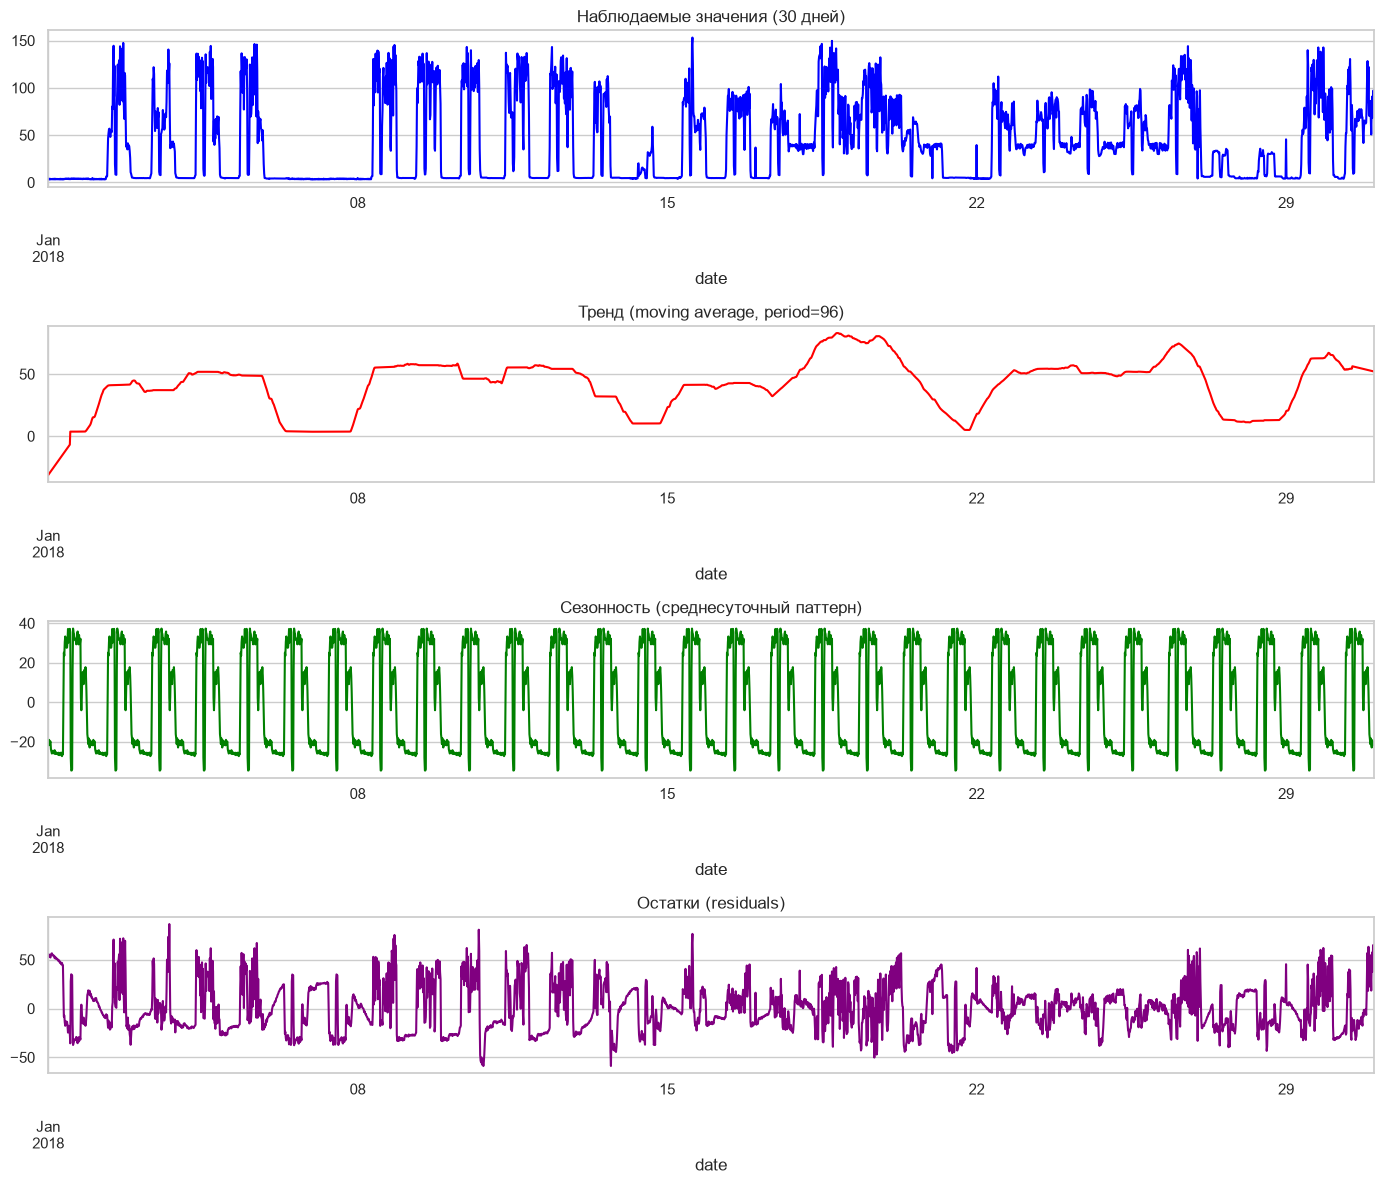

Статистика остатков аддитивной модели:
  Среднее: 0.5658
  Стд. отклонение: 23.8512
  Минимум: -58.8923
  Максимум: 86.6147


In [51]:
# Seasonal decomposition (trend + seasonal + residual)

# ~30 дней данных (2880 точек = 30 * 96)
decomp_window = df['Usage_kWh'].iloc[:2880]

# Аддитивная модель
decomp_add = seasonal_decompose(decomp_window, model='additive', period=96, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(14, 12))
decomp_add.observed.plot(ax=axes[0], color='blue')
axes[0].set_title('Наблюдаемые значения (30 дней)')

decomp_add.trend.plot(ax=axes[1], color='red')
axes[1].set_title('Тренд (moving average, period=96)')

decomp_add.seasonal.plot(ax=axes[2], color='green')
axes[2].set_title('Сезонность (среднесуточный паттерн)')

decomp_add.resid.plot(ax=axes[3], color='purple')
axes[3].set_title('Остатки (residuals)')

plt.tight_layout()
plt.show()

# Статистика остатков
print("Статистика остатков аддитивной модели:")
print(f"  Среднее: {decomp_add.resid.mean():.4f}")
print(f"  Стд. отклонение: {decomp_add.resid.std():.4f}")
print(f"  Минимум: {decomp_add.resid.min():.4f}")
print(f"  Максимум: {decomp_add.resid.max():.4f}")

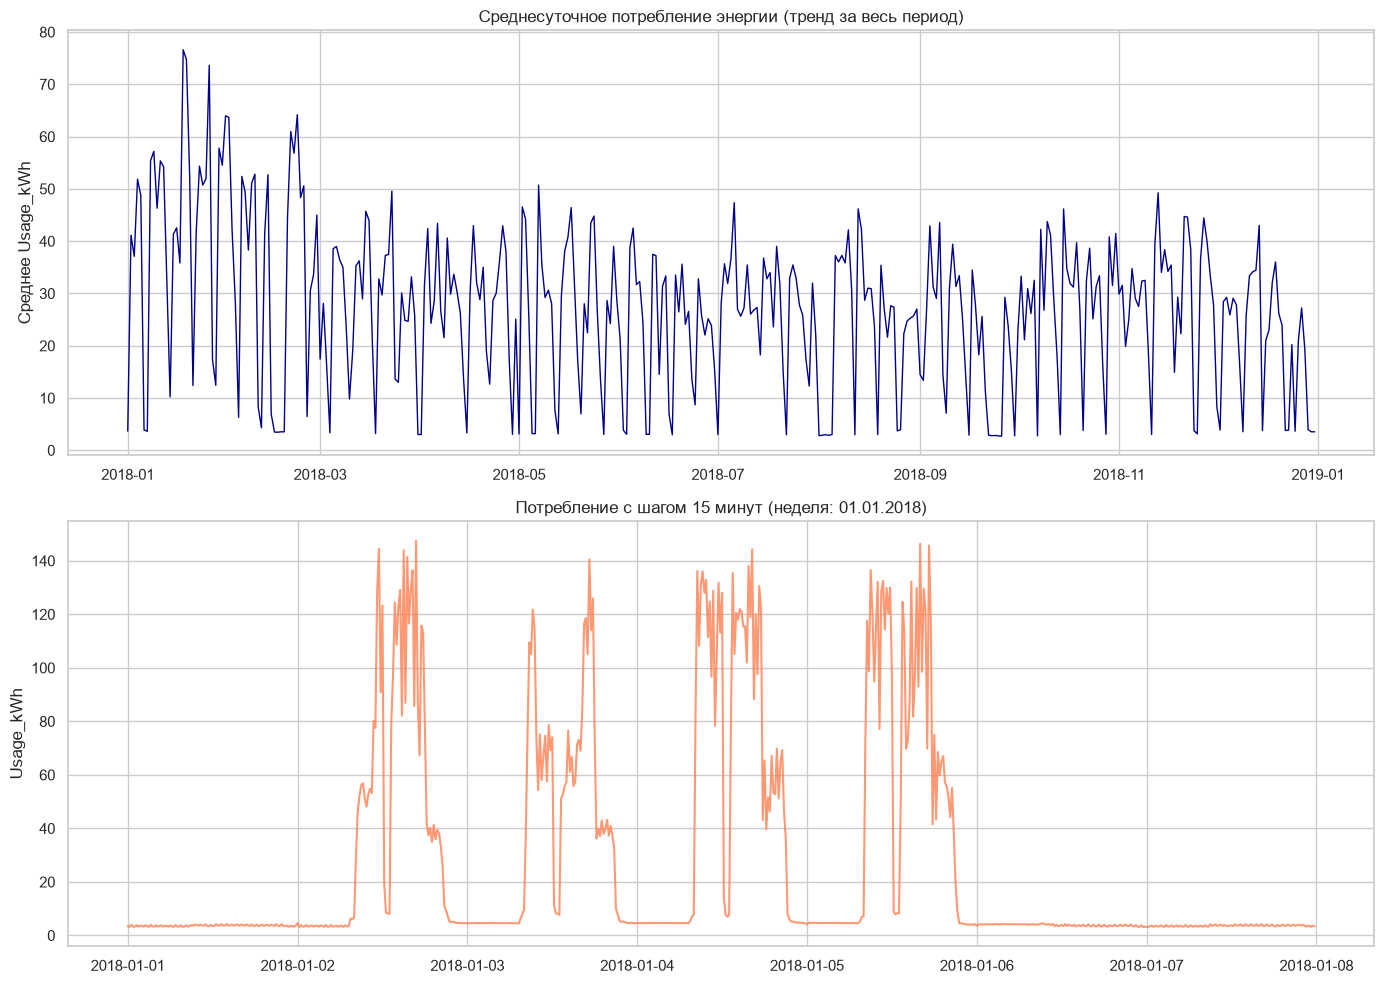

In [57]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# 1. Агрегация до среднего дневного потребления
daily_usage = df['Usage_kWh'].resample('D').mean()
axes[0].plot(daily_usage.index, daily_usage.values, color='darkblue', linewidth=1)
axes[0].set_title('Среднесуточное потребление энергии (тренд за весь период)')
axes[0].set_ylabel('Среднее Usage_kWh')

# 2. Первая полная неделя из данных (автоматически, не захардкожено)
first_full_week = df.index.min().to_period('W').start_time
week_start = pd.Timestamp(first_full_week)
week_end = week_start + pd.Timedelta(days=6, hours=23, minutes=45)
sample_week = df.loc[week_start:week_end]

if len(sample_week) > 0:
    axes[1].plot(sample_week.index, sample_week['Usage_kWh'], color='coral', alpha=0.8)
    axes[1].set_title(f'Потребление с шагом 15 минут (неделя: {week_start.strftime("%d.%m.%Y")})')
else:
    sample_week = df.iloc[:672]
    axes[1].plot(sample_week.index, sample_week['Usage_kWh'], color='coral', alpha=0.8)
    axes[1].set_title('Потребление с шагом 15 минут (первые 7 дней)')
axes[1].set_ylabel('Usage_kWh')

plt.tight_layout()
plt.show()

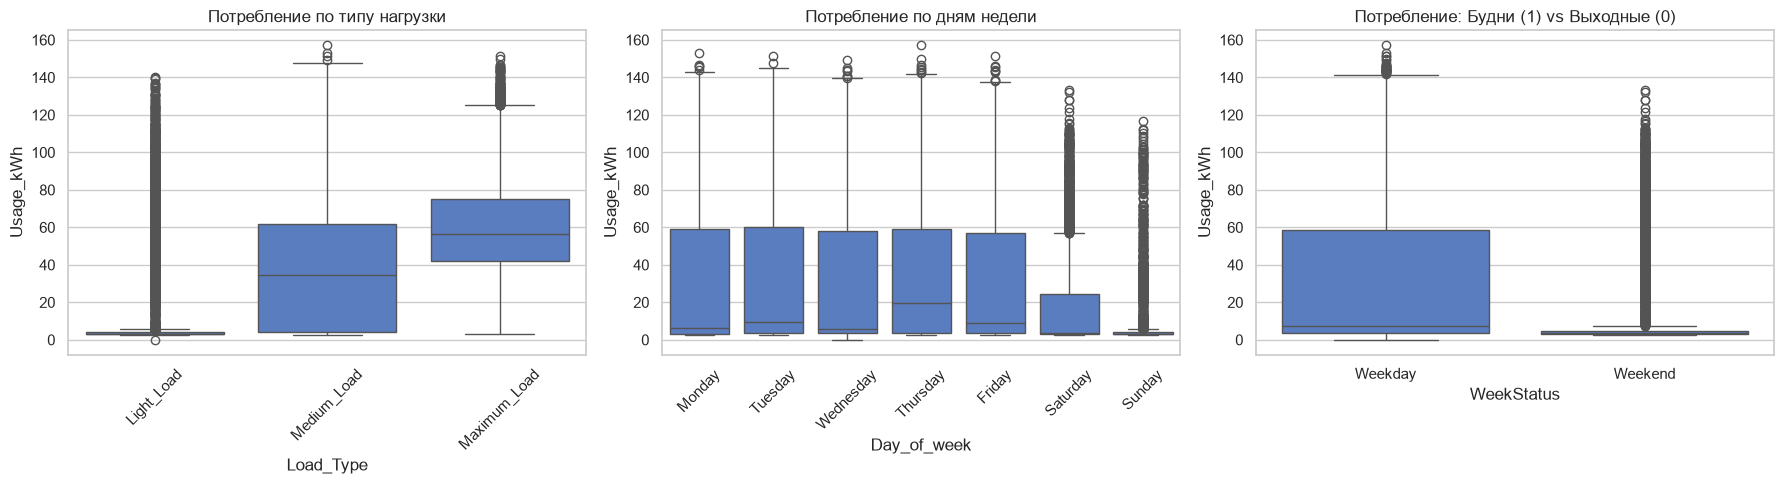

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Тип нагрузки
sns.boxplot(data=df, x='Load_Type', y='Usage_kWh', ax=axes[0], order=['Light_Load', 'Medium_Load', 'Maximum_Load'])
axes[0].set_title('Потребление по типу нагрузки')
axes[0].tick_params(axis='x', rotation=45)

# 2. День недели
sns.boxplot(data=df, x='Day_of_week', y='Usage_kWh', ax=axes[1])
axes[1].set_title('Потребление по дням недели')
axes[1].tick_params(axis='x', rotation=45)

# 3. Статус недели (Будни/Выходные)
sns.boxplot(data=df, x='WeekStatus', y='Usage_kWh', ax=axes[2])
axes[2].set_title('Потребление: Будни (1) vs Выходные (0)')

plt.tight_layout()
plt.show()

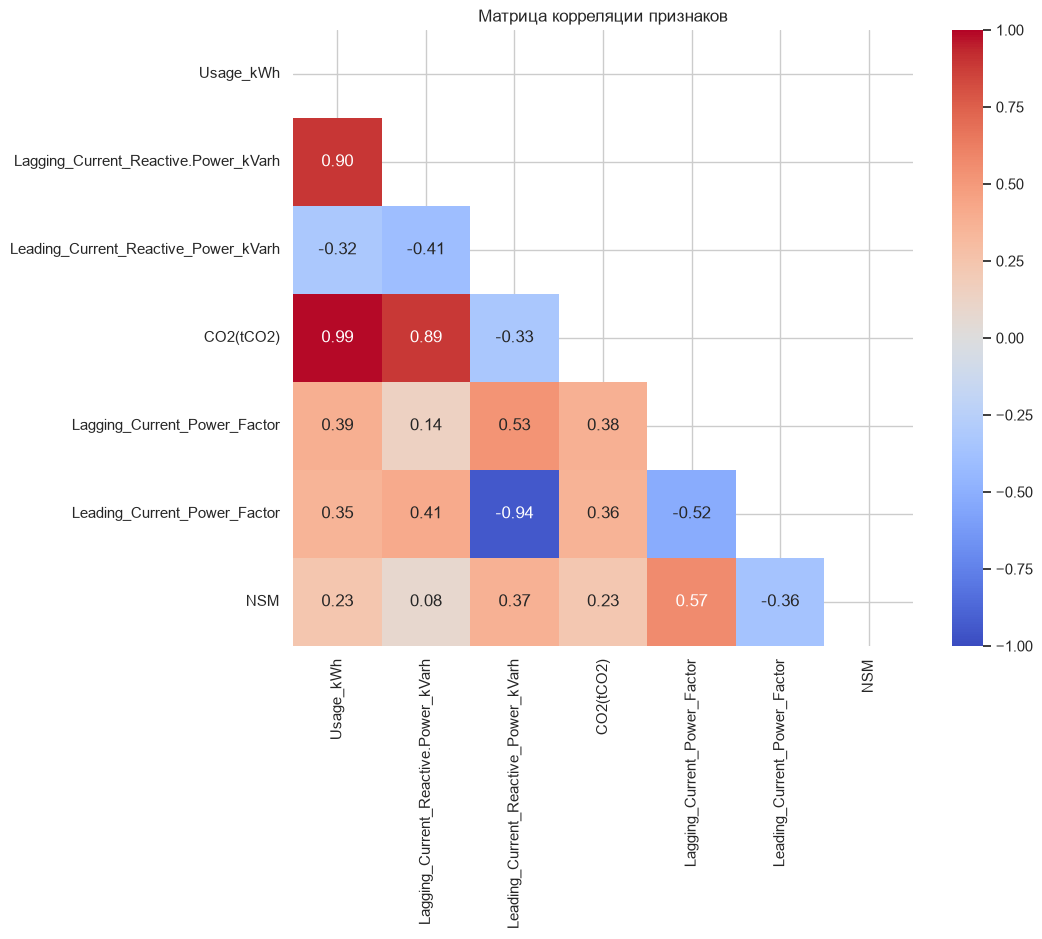


 Топ-5 признаков, наиболее коррелирующих с Usage_kWh:
CO2(tCO2)                               0.988180
Lagging_Current_Reactive.Power_kVarh    0.896150
Lagging_Current_Power_Factor            0.385960
Leading_Current_Power_Factor            0.353566
NSM                                     0.234610


In [54]:
# Выбираем только числовые столбцы для корреляции
numeric_df = df.select_dtypes(include=[np.number])

# Расчет матрицы корреляции Пирсона
corr_matrix = numeric_df.corr()

# Визуализация тепловой карты
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Маска для красоты (убирает дублирующийся треугольник)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матрица корреляции признаков')
plt.show()

# Вывод самых скоррелированных с целевой переменной признаков
target_corr = corr_matrix['Usage_kWh'].drop('Usage_kWh').sort_values(ascending=False)
print("\n Топ-5 признаков, наиболее коррелирующих с Usage_kWh:")
print(target_corr.head(5).to_string())

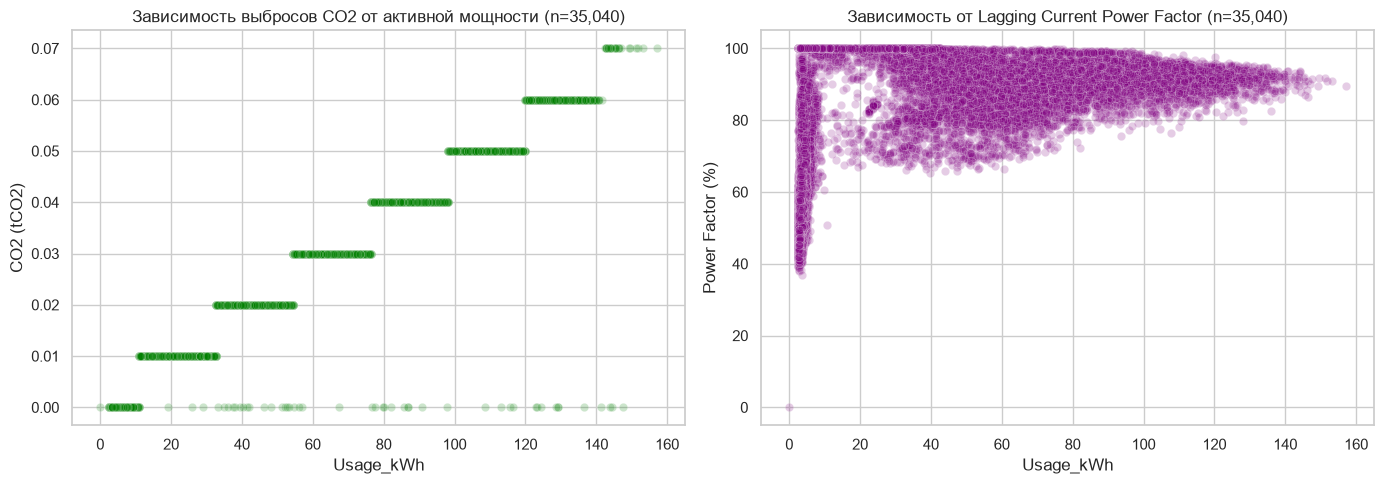

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

n_plot = min(50000, len(df))
df_sample = df.sample(n=n_plot, random_state=42)

# Scatter plot: Активная мощность vs CO2
sns.scatterplot(data=df_sample, x='Usage_kWh', y='CO2(tCO2)', alpha=0.2, ax=axes[0], color='green')
axes[0].set_title(f'Зависимость выбросов CO2 от активной мощности (n={n_plot:,})')
axes[0].set_xlabel('Usage_kWh')
axes[0].set_ylabel('CO2 (tCO2)')

# Scatter plot: Активная мощность vs Power Factor
sns.scatterplot(data=df_sample, x='Usage_kWh', y='Lagging_Current_Power_Factor', alpha=0.2, ax=axes[1], color='purple')
axes[1].set_title(f'Зависимость от Lagging Current Power Factor (n={n_plot:,})')
axes[1].set_xlabel('Usage_kWh')
axes[1].set_ylabel('Power Factor (%)')

plt.tight_layout()
plt.show()

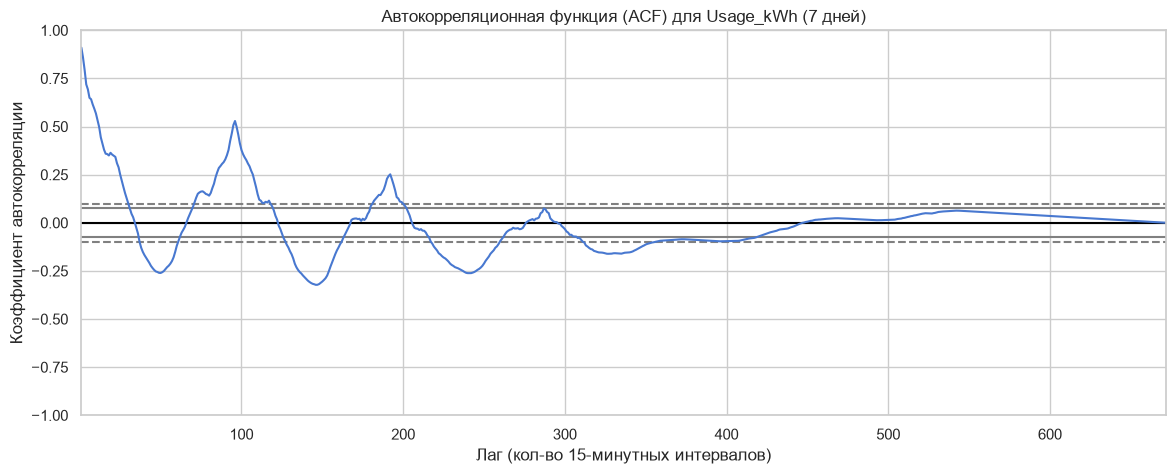

In [59]:
# ~7 дней — достаточно для выявления суточного паттерна (96 лагов)
sample_for_acf = df['Usage_kWh'].iloc[:672]

plt.figure(figsize=(14, 5))
autocorrelation_plot(sample_for_acf)
plt.title('Автокорреляционная функция (ACF) для Usage_kWh (7 дней)')
plt.xlabel('Лаг (кол-во 15-минутных интервалов)')
plt.ylabel('Коэффициент автокорреляции')
plt.grid(True)
plt.show()

### Ключевые выводы по результатам EDA:

---

#### 1. Целевая переменная (`Usage_kWh`)
- **Распределение**: сильное правостороннее — пик в области 0–10 kWh, длинный хвост до 157.18 kWh
- **Медиана**: 4.57 kWh, среднее: 27.39 kWh — значительно выше из-за выбросов
- **Выбросы**: не удалять — это реальные пиковые нагрузки завода

#### 2. Стационарность ряда (ADF-тест)
- Оригинальный ряд: t = -24.30, p < 0.001 → ряд СТАЦИОНАРЕН
- После 1-й разности: t = -40.90, p < 0.001 → ряд СТАЦИОНАРЕН
- После log-разности: t = -41.49, p < 0.001 → ряд СТАЦИОНАРЕН
- **Вывод**: ряд уже стационарен без преобразований, но разность и log-разность дают ещё более выраженный стационарный эффект

#### 3. Сезонная декомпозиция (30 дней, period=96)
- **Тренд**: нисходящий — среднесуточное потребление снизилось на ~40% за 2018 год (с 75 до 45 kWh в пике)
- **Сезонность**: суточный паттерн — пик в рабочие часы, спад ночью
- **Остатки**: среднее = 0.57, σ = 23.85, диапазон = -58.89 — 86.61
- **Вывод**: аддитивная модель адекватна (остатки близки к нулю по среднему)

#### 4. Целостность временного ряда
- Период: 2018-01-01 → 2018-12-31
- Ожидаемых записей: 35,040, фактических: 35,040
- Пропущенных интервалов: 0 → ряд целостный

#### 5. Календарные признаки
| Признак | Наблюдение |
|---|---|
| **Load_Type** | `Light_Load` — сильный предиктор, но аномальные выбросы до 140 kWh (требует аудита) |
| **Day_of_week** | Пн–Пт схожи, суббота — спад ~50%, воскресенье — минимум |
| **WeekStatus** | Значительное падение потребления в выходные; воскресенье — преимущественно нулевое |

#### 6. Корреляционный анализ
| Признак | Корреляция с Usage_kWh | Статус |
|---|---|---|
| `CO2(tCO2)` | **0.99** | Data leakage — 8 дискретных значений (0.00–0.07), расчётный индикатор |
| `Lagging_Current_Reactive.Power_kVarh` | **0.90** | Безопасный предиктор |
| `Leading_Current_Reactive_Power_kVarh` | отрицательная | Сильно коррелирует с `Leading_Current_Power_Factor` (-0.94) |

- **Нелинейность Power Factor**: при низкой нагрузке варьируется 0–100%, при высокой (>100 kWh) стабилизируется ~90–100%

#### 7. Автокорреляция (ACF, 7 дней)
| Лаг | Время | Интерпретация |
|---|---|---|
| 4 | 1 час | Внутренечасовая сезонность |
| 96 | 24 часа | Суточная сезонность — доминирует |
| 672 | 7 дней | Недельная сезонность |

---

### Рекомендации для Feature Engineering:

1. **Лаговые признаки**: `lag_1` (15 мин), `lag_4` (1 час), `lag_96` (сутки), `lag_672` (неделя)
2. **Скользящие статистики**: rolling mean и std за 4 интервала (1 час)
3. **Календарные признаки**: `hour`, `month`, `day_of_year`, `is_weekend`
4. **Исключить `CO2(tCO2)`** — риск data leakage (или использовать только лагированное значение)
5. **Не удалять выбросы** в `Usage_kWh` — это реальные пиковые нагрузки
6. **Валидация**: `TimeSeriesSplit` (случайное разбиение недопустимо из-за тренда и автокорреляции)
7. **Метрика**: **MAE**, loss: **Huber** (`objective='huber'`) для робастности к выбросам